In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from ydata_profiling import ProfileReport

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score
from scipy.stats import randint, loguniform

from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.preprocessing import FunctionTransformer
from sklearn.svm import SVC

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, f1_score

import time

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

import warnings
import random
import joblib
warnings.filterwarnings('ignore')

### Load the data from CSV Fie and analyse

In [2]:
# Open and read the input data file

vtd_df = pd.read_csv('data/synthetic_fleet_data_400k_splneeds.csv')


In [3]:
vtd_df.head()


,trip_id,trip_start_time,trip_end_time,trip_duration,total_distance,total_fuel,axle_weight_average,Group,Model,Serial Number,plant,Region,Country,manufacturer,wmi,GCW,GVW,Capacity,special_need
0,158815423,2022-11-07T00:00:00.000Z,2022-11-07T05:16:25.000Z,18985,337.59,64.02,3338,JHD500SERIES,500 Series,EU107265,JHDPLANT2,Europe,Netherlands,Hino,JHD,32.0,16.0,9.0,Flatbed
1,155624719,2019-02-06T00:00:00.000Z,2019-02-08T19:04:23.000Z,241463,2246.18,671.50,7748,VF6THIGH,T High,EU638569,VF6PLANT1,Europe,France,Renault,VF6,44.0,26.0,24.0,Refrigerated
2,151582622,2021-05-03T00:00:00.000Z,2021-05-05T18:14:03.000Z,238443,2236.45,721.41,6850,YS2R-SERIES,R-Series,EU211030,YS2PLANT1,Europe,Italy,Scania,YS2,44.0,26.0,24.0,Container
3,801093661,2019-06-12T00:00:00.000Z,2019-06-14T18:47:02.000Z,240422,2360.56,623.42,11019,YV2FH16,FH16,EU554151,YV2PLANT3,Europe,Sweden,Volvo,YV2,60.0,32.0,40.0,Heavy Haulage
4,114274592,2022-08-15T00:00:00.000Z,2022-08-15T05:58:01.000Z,21481,371.97,78.12,6725,JHD500SERIES,500 Series,EU701763,JHDPLANT4,Europe,Spain,Hino,JHD,32.0,16.0,9.0,Box


### Feature Definitions (ML Context)

    trip_id
    Unique identifier for each trip record.


    trip_start_time
    Timestamp when the trip begins.


    trip_end_time
    Timestamp when the trip ends.


    trip_duration
    Total trip time (usually seconds/minutes).


    total_distance
    Total kilometres travelled in the trip.


    total_fuel
    Total fuel consumed during the trip (litres).


    axle_weight_average
    Average load per axle during the trip.


    Group
    Vehicle classification group (e.g., light, medium, heavy).


    Model
    Specific vehicle model.


    Serial Number
    Manufacturer-assigned unique ID for the vehicle.


    Asset_ID
    Fleet Operators system ID for the vehicle.


    manufacturer
    OEM/brand of the vehicle (e.g., Tata, Volvo).


    wmi
    World Manufacturer Identifier (first 3 VIN characters).


    plant
    Facility or site where the vehicle operates.


    Region
    Geographic region (e.g., APAC, Europe).


    Country
    Country of operation.


    GVW (Gross Vehicle Weight)
    Maximum allowable weight of the vehicle including cargo, fuel, and passengers.


    GCW (Gross Combination Weight)
    Total weight of vehicle + trailer + load.


    Capacity
    Payload capacity (maximum cargo weight).

    special_need
    Indicator for special vehicle requirements (e.g., refrigeration, hazardous goods).


In [4]:
vtd_df.describe

<bound method NDFrame.describe of           trip_id           trip_start_time             trip_end_time  \
0       158815423  2022-11-07T00:00:00.000Z  2022-11-07T05:16:25.000Z   
1       155624719  2019-02-06T00:00:00.000Z  2019-02-08T19:04:23.000Z   
2       151582622  2021-05-03T00:00:00.000Z  2021-05-05T18:14:03.000Z   
3       801093661  2019-06-12T00:00:00.000Z  2019-06-14T18:47:02.000Z   
4       114274592  2022-08-15T00:00:00.000Z  2022-08-15T05:58:01.000Z   
...           ...                       ...                       ...   
399995  648465863  2020-07-19T00:00:00.000Z  2020-07-19T04:18:02.000Z   
399996  894965358  2018-04-11T00:00:00.000Z  2018-04-11T00:11:42.000Z   
399997  677143064  2019-07-06T00:00:00.000Z  2019-07-06T01:49:42.000Z   
399998  933992428  2021-04-18T00:00:00.000Z  2021-04-18T02:52:27.000Z   
399999  192010008  2019-11-29T00:00:00.000Z  2019-11-29T06:30:06.000Z   

        trip_duration  total_distance  total_fuel  axle_weight_average  \
0              

In [5]:
vtd_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400000 entries, 0 to 399999
Data columns (total 19 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   trip_id              400000 non-null  int64  
 1   trip_start_time      400000 non-null  object 
 2   trip_end_time        400000 non-null  object 
 3   trip_duration        400000 non-null  int64  
 4   total_distance       400000 non-null  float64
 5   total_fuel           400000 non-null  float64
 6   axle_weight_average  400000 non-null  int64  
 7   Group                400000 non-null  object 
 8   Model                400000 non-null  object 
 9   Serial Number        400000 non-null  object 
 10  plant                400000 non-null  object 
 11  Region               400000 non-null  object 
 12  Country              400000 non-null  object 
 13  manufacturer         400000 non-null  object 
 14  wmi                  400000 non-null  object 
 15  GCW              

#### Drop the colum thats not a value add long with data category 
##### this data category was realized in data prepration stage and was then looped to inital stage and dropped

In [6]:
#droppping the Trip ID  and abulance data from the speial needs column 

vtd_df = vtd_df.drop(columns= ['trip_id'])
vtd_df = vtd_df[vtd_df['special_need'].str.lower() != 'ambulance']

In [7]:
#convert the trip start and trip end columns to date

vtd_df['trip_start_time'] = pd.to_datetime(vtd_df['trip_start_time']).dt.date
vtd_df['trip_end_time'] = pd.to_datetime(vtd_df['trip_end_time']).dt.date

In [8]:
#combining the Make and model columns to bring more value as this s a unique combination given that each OE wil have multiple models and sometimes these model names can be overlapping , however a 
# make + mdoel conbination will make it unique

vtd_df['Make_n_Model'] = vtd_df['manufacturer'] + '_' + vtd_df['Model']

In [9]:
# identifying the target column (y) that will be predicted by the model 

target_col = 'Make_n_Model'

In [10]:
vtd_df.head()

,trip_start_time,trip_end_time,trip_duration,total_distance,total_fuel,axle_weight_average,Group,Model,Serial Number,plant,Region,Country,manufacturer,wmi,GCW,GVW,Capacity,special_need,Make_n_Model
0,2022-11-07,2022-11-07,18985,337.59,64.02,3338,JHD500SERIES,500 Series,EU107265,JHDPLANT2,Europe,Netherlands,Hino,JHD,32.0,16.0,9.0,Flatbed,Hino_500 Series
1,2019-02-06,2019-02-08,241463,2246.18,671.50,7748,VF6THIGH,T High,EU638569,VF6PLANT1,Europe,France,Renault,VF6,44.0,26.0,24.0,Refrigerated,Renault_T High
2,2021-05-03,2021-05-05,238443,2236.45,721.41,6850,YS2R-SERIES,R-Series,EU211030,YS2PLANT1,Europe,Italy,Scania,YS2,44.0,26.0,24.0,Container,Scania_R-Series
3,2019-06-12,2019-06-14,240422,2360.56,623.42,11019,YV2FH16,FH16,EU554151,YV2PLANT3,Europe,Sweden,Volvo,YV2,60.0,32.0,40.0,Heavy Haulage,Volvo_FH16
4,2022-08-15,2022-08-15,21481,371.97,78.12,6725,JHD500SERIES,500 Series,EU701763,JHDPLANT4,Europe,Spain,Hino,JHD,32.0,16.0,9.0,Box,Hino_500 Series


### Exploratory Data Analysis

In [11]:
vtd_df['Capacity'].unique()

array([ 9. , 24. , 40. ,  4. , 10. ,  8. ,  2.5,  6. ,  1.5])

In [12]:
vtd_df[target_col].unique()

array(['Hino_500 Series', 'Renault_T High', 'Scania_R-Series',
       'Volvo_FH16', 'Fuso_Canter', 'Scania_S-Series V8',
       'Iveco_Eurocargo', 'Iveco_Daily', 'Mercedes_Actros',
       'Mercedes_Atego', 'DAF_XG+', 'Volvo_FL', 'Mercedes_Sprinter',
       'MAN_TGE', 'Volvo_FH', 'MAN_TGL', 'Isuzu_N-Series',
       'Renault_Master', 'Iveco_S-Way', 'DAF_LF', 'MAN_TGX'], dtype=object)

In [13]:
#check for missing values in the dataset

missing_values = vtd_df.isnull().sum()
print(missing_values) 

trip_start_time        0
trip_end_time          0
trip_duration          0
total_distance         0
total_fuel             0
axle_weight_average    0
Group                  0
Model                  0
Serial Number          0
plant                  0
Region                 0
Country                0
manufacturer           0
wmi                    0
GCW                    0
GVW                    0
Capacity               0
special_need           0
Make_n_Model           0
dtype: int64


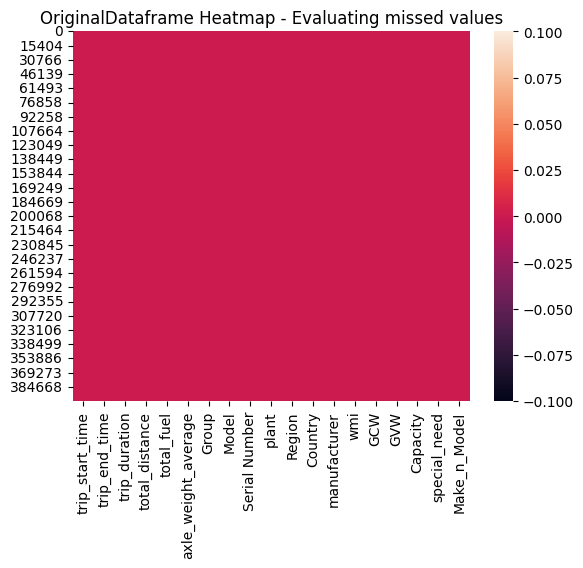

In [14]:
# Visually Checking for any missing data in a heatmap so that it can be imputed later on
 
heatmap = sns.heatmap(
	vtd_df.isna()
)
heatmap.set_title("OriginalDataframe Heatmap - Evaluating missed values")
plt.show()

In [15]:
# creating a  profile report for the data set to help in EDA using ydata_profiling

profile = ProfileReport(vtd_df, title="Vehicle Trip Data Profiling Report", explorative=True)
profile.to_file("data/vehicle_trip_profile_report.html") 

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 19/19 [00:06<00:00,  3.01it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [16]:
profile

                     trip_duration  total_distance  total_fuel  \
trip_duration             1.000000        0.982388    0.973612   
total_distance            0.982388        1.000000    0.990795   
total_fuel                0.973612        0.990795    1.000000   
axle_weight_average       0.643163        0.692129    0.694750   
GCW                       0.660386        0.713198    0.714631   
GVW                       0.682456        0.735858    0.738003   
Capacity                  0.689212        0.733143    0.740472   

                     axle_weight_average       GCW       GVW  Capacity  
trip_duration                   0.643163  0.660386  0.682456  0.689212  
total_distance                  0.692129  0.713198  0.735858  0.733143  
total_fuel                      0.694750  0.714631  0.738003  0.740472  
axle_weight_average             1.000000  0.869450  0.889567  0.821041  
GCW                             0.869450  1.000000  0.974935  0.956739  
GVW                             0

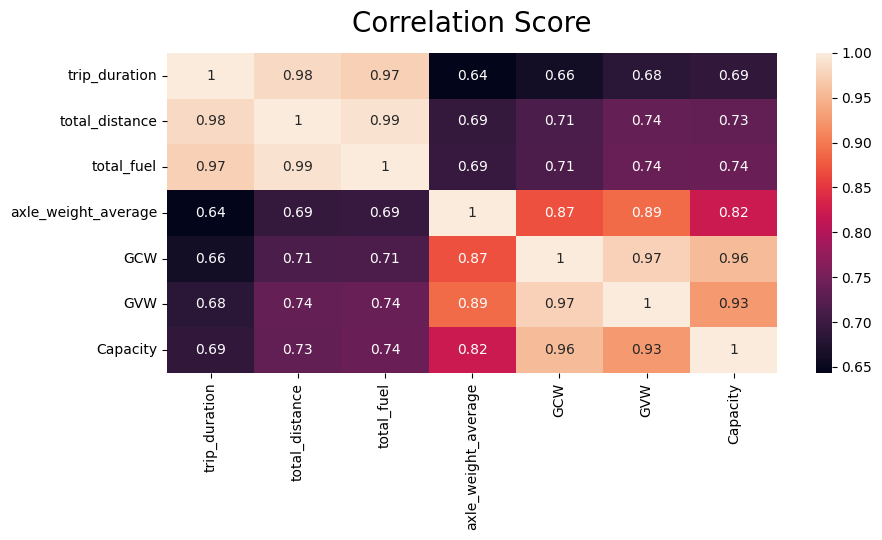

In [17]:
#plotting a correlation matrix to see the correlation between the numerical features in our dataset

correlation_matrix = vtd_df.corr(numeric_only=True)

print (correlation_matrix)

plt.figure(figsize=(9.5,5.5))
plt.title('Correlation Score', fontsize=20, pad=15)
sns.heatmap(correlation_matrix, annot=True)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
#Duration Special needs v.s Trip Duration
 
fig = px.box(vtd_df, x="special_need", y="trip_duration",  color="special_need")
fig.update_traces(quartilemethod="exclusive") # or "inclusive", or "linear" by default
fig.show()

In [19]:
fig = px.box(vtd_df, x="special_need", y="total_fuel", color="special_need")
fig.update_traces(quartilemethod="exclusive") # or "inclusive", or "linear" by default
fig.show()

In [20]:
fig = px.box(vtd_df, x="special_need", y="total_distance", color='special_need',title='Special Needs vs Total Distance')
fig.update_layout(xaxis_tickangle=45)
fig.show()

Text(0, 0.5, 'special_need')

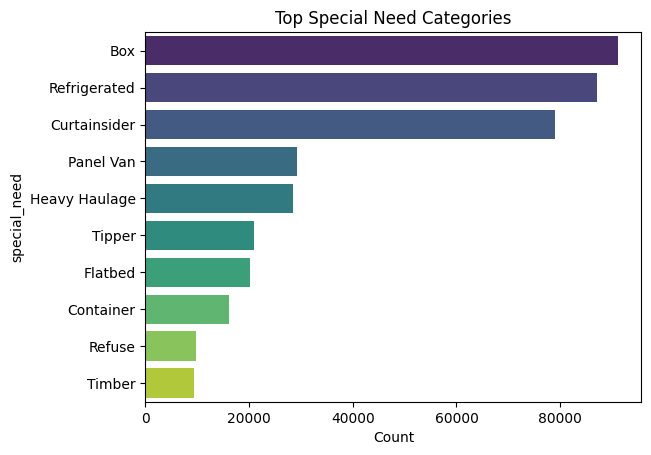

In [21]:
top_special_need = vtd_df['special_need'].value_counts().nlargest(10)
sns.barplot(x=top_special_need.values, y=top_special_need.index, palette='viridis')
plt.title('Top Special Need Categories')
plt.xlabel('Count')
plt.ylabel('special_need')

In [22]:
#total distance vs Duration calls

fig = px.scatter(vtd_df, x="total_distance", y="trip_duration", color='special_need')
fig.show()

Text(0.5, 0, 'Trip Duration (seconds)')

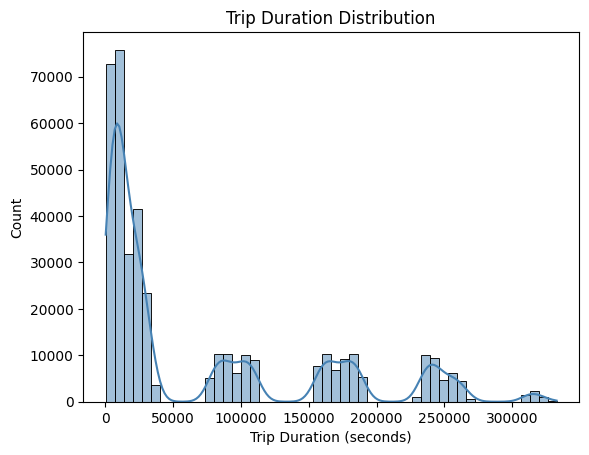

In [23]:
sns.histplot(vtd_df['trip_duration'], bins=50, kde=True, color='steelblue')
plt.title('Trip Duration Distribution')
plt.xlabel('Trip Duration (seconds)')

<Axes: xlabel='special_need'>

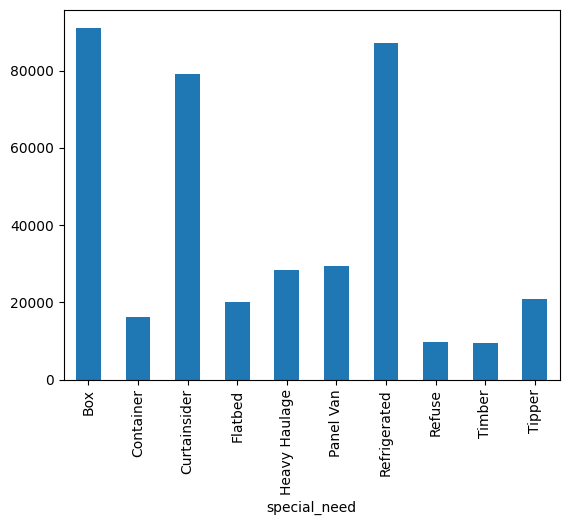

In [24]:
vtd_df['special_need'].value_counts().sort_index().plot(kind='bar')

In [25]:
# plotting the special needs vs the make and model of the vehicle to see if there is any correlation between the two features

counts = pd.crosstab(vtd_df['Make_n_Model'], vtd_df['special_need'])

# Build stacked bars
fig = go.Figure()

for col in counts.columns:
    fig.add_trace(
        go.Bar(
            x=counts.index,
            y=counts[col],
            name=str(col)
        )
    )

fig.update_layout(
    barmode='stack',
    width=1600,
    height=800
)

fig.show()

In [26]:
# monthly distribution of calls
fig = px.histogram(vtd_df, x='trip_start_time', nbins=6)
fig.update_layout(title='Yearly Distribution of Trips', xaxis_title='Year', yaxis_title='Count',bargap=0.2)
fig.show()

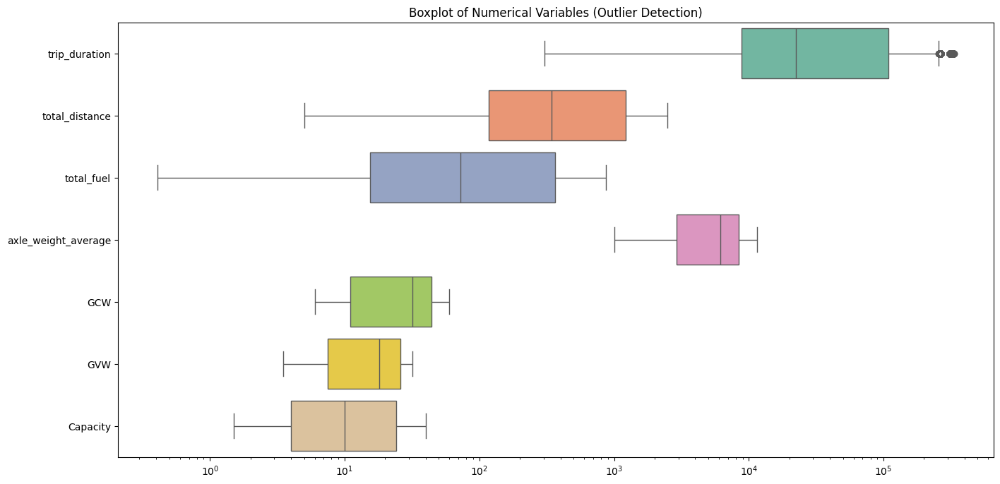

In [27]:
# Box plots to detect outliers
plt.figure(figsize=(16, 8))
sns.boxplot(data=vtd_df.select_dtypes(include=[np.number]), orient="h", palette="Set2")
plt.title("Boxplot of Numerical Variables (Outlier Detection)")
plt.xscale('log')
plt.show()


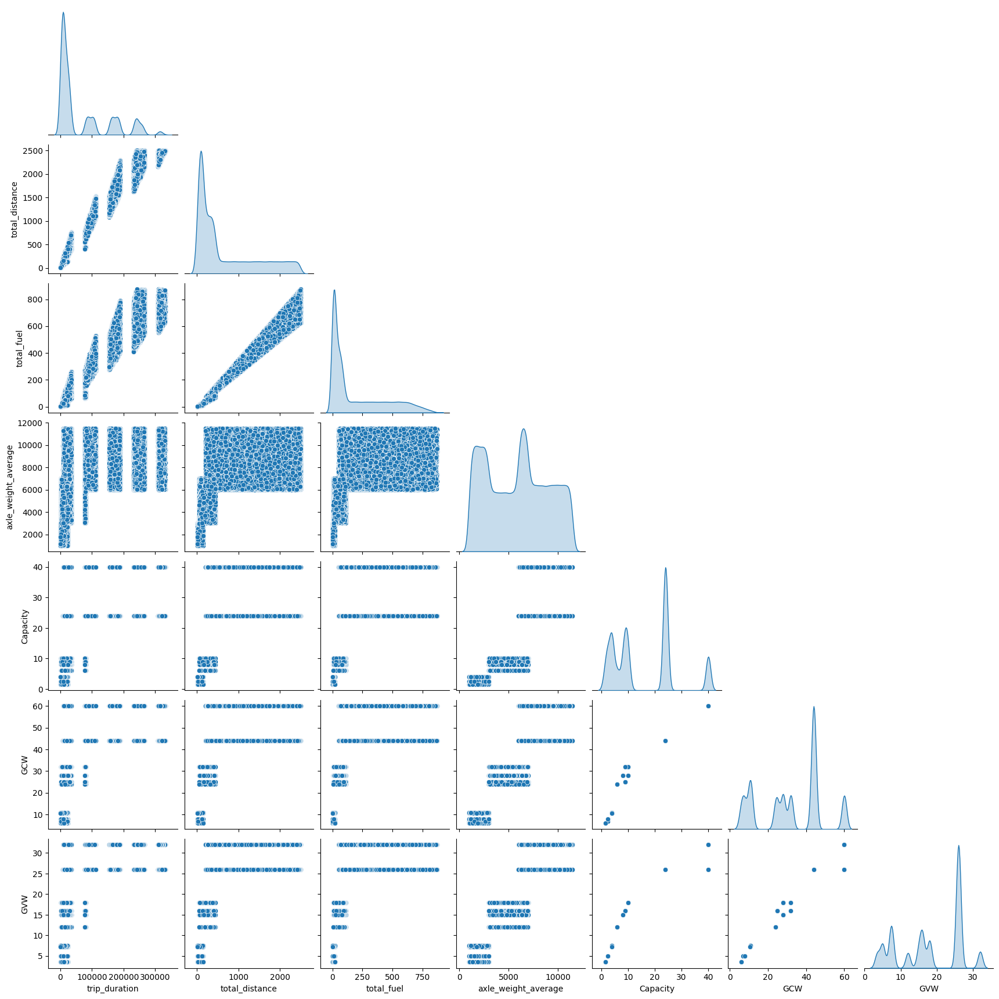

In [28]:
selected_features = [    
    'trip_duration',
    'total_distance',
    'total_fuel',
    'axle_weight_average',
    'Capacity',
    'GCW',
    'GVW']
sns.pairplot(vtd_df[selected_features], diag_kind="kde", corner=True)

In [29]:
vtd_df.groupby('special_need')[target_col].describe()

,count,unique,top,freq
special_need,,,,
Box,91111,10,Mercedes_Atego,10482
Container,16091,2,Iveco_S-Way,9592
Curtainsider,79073,9,Volvo_FH,10447
Flatbed,20121,2,Hino_500 Series,11238
Heavy Haulage,28387,2,Volvo_FH16,20667
Panel Van,29305,3,Mercedes_Sprinter,10526
Refrigerated,87065,10,Mercedes_Actros,11260
Refuse,9738,1,Volvo_FL,9738
Timber,9366,1,Scania_S-Series V8,9366


### Modeling 

In [30]:
#dropping the target colummn for the dataframe

vtd_df = vtd_df.dropna(subset=[target_col])

In [31]:
#declaring the numeric and categorical features 

raw_numeric_features = [
    'trip_duration',
    'total_distance',
    'total_fuel',
    'axle_weight_average',
    'Capacity',
    'GCW',
    'GVW'
]

numeric_features = raw_numeric_features 

categorical_features = [
    'special_need'
    #'Group' - in gemini synthetic data this is nto relevant
]


In [32]:
#combining Numerical and categorical feaures to create the feature pool that will be exteacted into definig the  X - Test and training data sets
features = numeric_features + categorical_features
features

['trip_duration',
 'total_distance',
 'total_fuel',
 'axle_weight_average',
 'Capacity',
 'GCW',
 'GVW',
 'special_need']

In [33]:
X = vtd_df[features]
y = vtd_df[target_col]

In [34]:
X

,trip_duration,total_distance,total_fuel,axle_weight_average,Capacity,GCW,GVW,special_need
0,18985,337.59,64.02,3338,9.0,32.0,16.0,Flatbed
1,241463,2246.18,671.50,7748,24.0,44.0,26.0,Refrigerated
2,238443,2236.45,721.41,6850,24.0,44.0,26.0,Container
3,240422,2360.56,623.42,11019,40.0,60.0,32.0,Heavy Haulage
4,21481,371.97,78.12,6725,9.0,32.0,16.0,Box
...,...,...,...,...,...,...,...,...
399995,15482,312.42,52.68,4856,6.0,24.0,12.0,Curtainsider
399996,702,6.76,0.93,1786,4.0,10.5,7.2,Box
399997,6582,135.45,29.39,4243,9.0,32.0,16.0,Flatbed
399998,10347,158.41,26.56,4819,8.0,28.0,15.0,Box


### Function to support Derived feature generation into the pipeline for the modeling

In [35]:
def add_derived_features(X):
    X = X.copy()
    X['trip_duration_hours'] = X['trip_duration'] / 3600
    X['fuel_per_km'] = np.where(
        X['total_distance'] > 0,
        X['total_fuel'] / X['total_distance'],
        np.nan
    )
    X['avg_speed_kmph'] = np.where(
        X['trip_duration_hours'] > 0,
        X['total_distance'] / X['trip_duration_hours'],
        np.nan
    )
    return X

In [36]:

feature_generator = FunctionTransformer(add_derived_features, validate=False)

In [37]:
# pipeline definition for preprocessing

numeric_transformer  = Pipeline(
    steps=[
        #('imputer', SimpleImputer(strategy = 'median')), -> no inputation as we dont have any missing data 
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps = [
        #('imputer', SimpleImputer(strategy = 'most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

numeric_features = numeric_features + [
    'trip_duration_hours', 'fuel_per_km', 'avg_speed_kmph'
]

preprocessor_ct = ColumnTransformer(
    transformers = [
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

preprocessor_ct

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,copy,True
,with_mean,True
,with_std,True


In [38]:
#  Split data into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, shuffle=True, random_state=42)

In [39]:
# Ensure derived features are created automatically inside the preprocessing step
# updating the pipeline to include the defived features are added before we call the numberic and categorical transformers

preprocessor = Pipeline(steps=[
    ('feature_generator', feature_generator),   # adds trip_duration_hours, fuel_per_km, avg_speed_kmph
    ('column_transformer', preprocessor_ct)  # then applies the existing ColumnTransformer
])

# Helper to build model pipelines that will now create derived features automatically
def make_pipeline_with_features(model):
    return Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

# quick sanity check (does not overwrite X_train/X_test)
X_train_check = feature_generator.transform(X_train)
print("Derived cols in X_train_check:", [c for c in X_train_check.columns if c in ['trip_duration_hours','fuel_per_km','avg_speed_kmph']])

X_train_check

preprocessor

Derived cols in X_train_check: ['trip_duration_hours', 'fuel_per_km', 'avg_speed_kmph']


,steps,"[('feature_generator', ...), ('column_transformer', ...)]"
,transform_input,None
,memory,None
,verbose,False
,func,<function add...002C407414400>
,inverse_func,None
,validate,False
,accept_sparse,False
,check_inverse,True
,feature_names_out,None
,kw_args,None


In [40]:

X_fg = feature_generator.transform(X_train)

print("Shape after feature_generator:", X_fg.shape)
print("New columns:",
      [c for c in X_fg.columns if c in ['trip_duration_hours','fuel_per_km','avg_speed_kmph']])

X_fg.head()

Shape after feature_generator: (312963, 11)
New columns: ['trip_duration_hours', 'fuel_per_km', 'avg_speed_kmph']


,trip_duration,total_distance,total_fuel,axle_weight_average,Capacity,GCW,GVW,special_need,trip_duration_hours,fuel_per_km,avg_speed_kmph
286693,8527,134.68,13.45,1397,2.5,8.0,5.0,Panel Van,2.368611,0.099866,56.860326
389220,102410,1023.43,334.57,11477,24.0,44.0,26.0,Container,28.447222,0.326910,35.976448
256621,77554,723.70,215.71,10592,24.0,44.0,26.0,Container,21.542778,0.298065,33.593625
206325,8250,130.41,17.82,2191,4.0,10.5,7.2,Refrigerated,2.291667,0.136646,56.906182
171202,6991,135.98,26.08,5185,8.0,28.0,15.0,Curtainsider,1.941944,0.191793,70.022600


In [41]:
X_full = preprocessor.fit_transform(X_train, y_train)

print("Shape after full preprocessor:", X_full.shape)
print(type(X_full))

Shape after full preprocessor: (312963, 20)
<class 'numpy.ndarray'>


In [42]:
# test step to check if the derived feature addition step is working correctly 
 
feature_names = preprocessor.named_steps['column_transformer'].get_feature_names_out()

df_full = pd.DataFrame(X_full, columns=feature_names)

print([col for col in feature_names 
       if 'trip_duration_hours' in col 
       or 'fuel_per_km' in col 
       or 'avg_speed_kmph' in col])

['num__trip_duration_hours', 'num__fuel_per_km', 'num__avg_speed_kmph']


###  Simple Model comparision

Use Logistic Regression, KNN, Decisioun Tree and SVM to build a basic model on data. 

In [43]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(),
    "SVM": SVC(kernel='linear')
}

In [44]:
#initiating a dictionary to store the results
results = {
    "Model": [],
    "Train Time": [],
    "Train Accuracy": [],
    "Test Accuracy": [],
    "Precision": [],
    "F1 Score": [],
    "ROC-AUC": [],            
    "Confusion Matrix": [], 
    "Best Params":[]
}

In [45]:

pipelines = {} 

for name, model in models.items():
    pipelines[name] = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

for name, pipeline in pipelines.items():
    print(f"Evaluating {name}...")
    
    start_time = time.time()
    pipeline.fit(X_train, y_train)
    train_time = time.time() - start_time

    y_pred = pipeline.predict(X_test)

    if hasattr(pipeline, "predict_proba"):
        y_proba = pipeline.predict_proba(X_test)
        
        if y_proba.shape[1] > 2:  #  multiclass
            roc_auc = roc_auc_score(y_test, y_proba, multi_class='ovr', average='weighted')
        else:  #  binary
            roc_auc = roc_auc_score(y_test, y_proba[:, 1])

    else:
        #  Not reliable for multiclass → set NaN
        roc_auc = float('nan')

    precision = precision_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    cm = confusion_matrix(y_test, y_pred)

    results["Model"].append(name)
    results["Train Time"].append(train_time)
    results["Train Accuracy"].append(pipeline.score(X_train, y_train))
    results["Test Accuracy"].append(pipeline.score(X_test, y_test))
    results["Precision"].append(precision)
    results["F1 Score"].append(f1)
    results["ROC-AUC"].append(roc_auc)
    results["Confusion Matrix"].append(cm)  
    results["Best Params"].append('nan')  

Evaluating Logistic Regression...
Evaluating K-Nearest Neighbors...
Evaluating Decision Tree...
Evaluating SVM...


In [46]:
#converting the dictionary into a dataframe
results_df = pd.DataFrame(results)
results_df

,Model,Train Time,Train Accuracy,Test Accuracy,Precision,F1 Score,ROC-AUC,Confusion Matrix,Best Params
0,Logistic Regression,210.342194,0.719229,0.716760,0.761879,0.704931,0.961490,"[[3514, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",nan
1,K-Nearest Neighbors,1.060536,0.788381,0.678123,0.680274,0.676842,0.908344,"[[3514, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",nan
2,Decision Tree,11.389583,1.000000,0.702816,0.702805,0.702801,0.843434,"[[3514, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",nan
3,SVM,1817.994731,0.719143,0.716568,0.726024,0.697210,NaN,"[[3514, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",nan


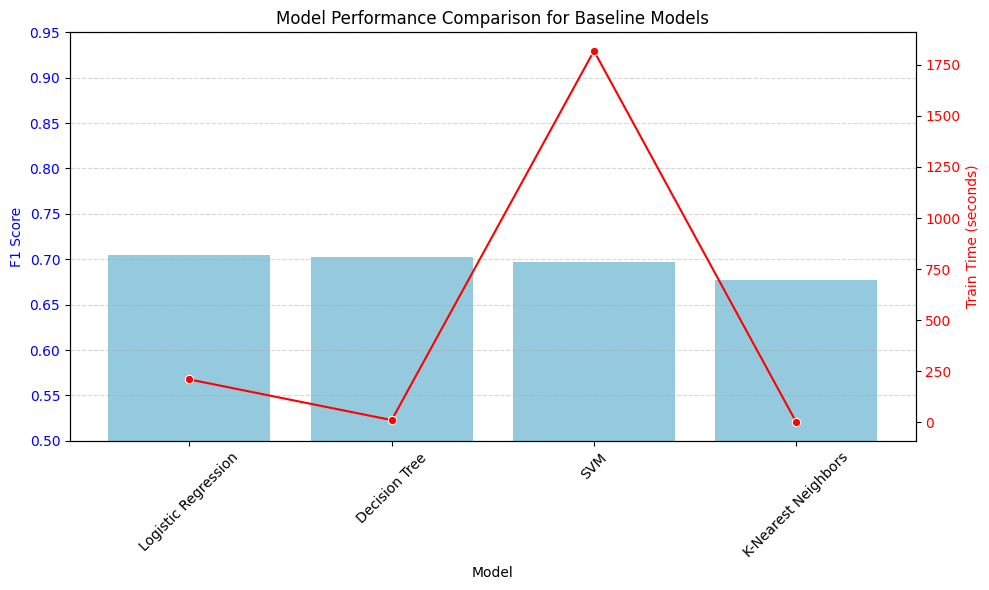

In [47]:
# plot a graph with bars for test accuracy and line graph for train time in a single graph
# zoom on accuracy between 0.5 and 0.95

plot_df = results_df.copy()

plot_df = plot_df.sort_values('F1 Score', ascending=False).reset_index(drop=True)

fig, ax1 = plt.subplots(figsize=(10, 6))
sns.barplot(x='Model', y='F1 Score', data=plot_df, ax=ax1, color='skyblue')
ax1.set_xlabel('Model')
ax1.set_ylabel('F1 Score', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_ylim(0.5, 0.95)

ax2 = ax1.twinx()
sns.lineplot(x='Model', y='Train Time', data=plot_df, ax=ax2, color='red', marker='o')
ax2.set_ylabel('Train Time (seconds)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

plt.title('Model Performance Comparison for Baseline Models')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


#### SVM seams to have taken the max time but Logistic regression has the best F1 score amongst the 4 models

### ROC-AUC analysis

In [48]:
# Pick best model by ROC-AUC
best_model_name = results_df.sort_values(by="ROC-AUC", ascending=False).iloc[0]["Model"]

print(f"Best model: {best_model_name}")

Best model: Logistic Regression


In [49]:
best_pipeline = pipelines[best_model_name]

In [50]:
y_proba = best_pipeline.predict_proba(X_test)

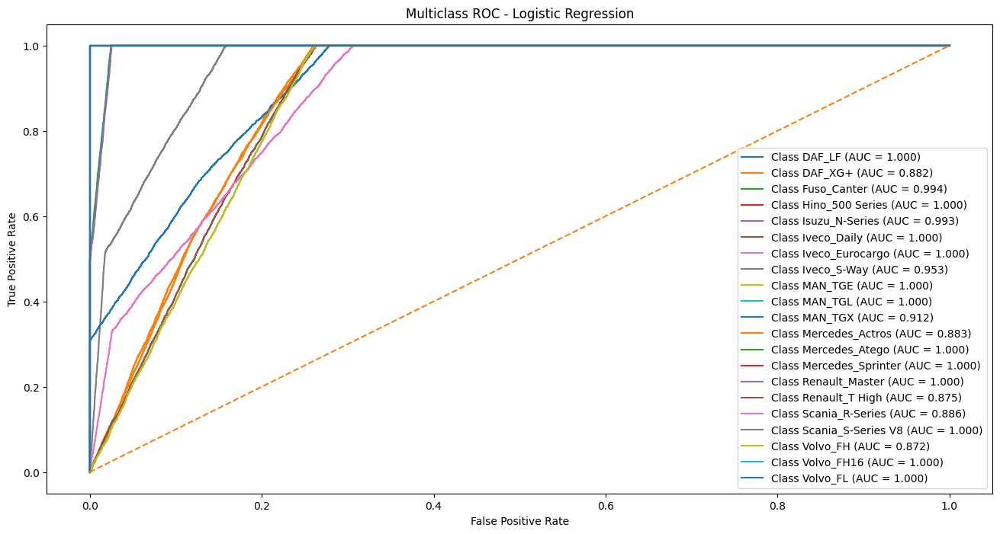

In [51]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

classes = sorted(set(y_test))
y_test_bin = label_binarize(y_test, classes=classes)


plt.figure(figsize=(16, 8))

for i in range(len(classes)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'Class {classes[i]} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'Multiclass ROC - {best_model_name}')
plt.legend()

plt.show()

### Hyper parameter tunning to see if we improve the F1 score across these models


In [52]:
random_state=42

In [ ]:
# Models to be used for classification are KNN> Logistic regression , Decision tree and SVM

'''models = {
    'KNN': KNeighborsClassifier(),
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest' : RandomForestClassifier()
}'''

models = {
    'KNN Tuned': KNeighborsClassifier(),

    'Logistic Regression Tuned': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Decision Tree Tuned': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest Tuned': RandomForestClassifier(
        random_state=42
    ),

    'SVM Tuned': SVC(
        probability=True,   # Important for ROC-AUC
        random_state=42
    )
}

: 

#### Using RandomSearchCV with C value of 3 to iterate between the models across hyperparameter to find the best model for the prediction

In [ ]:

# Random Search parameter 

param_distributions = {
    'KNN Tuned': {
        'classifier__n_neighbors': randint(3, 15),
        'classifier__weights': ['uniform', 'distance'],
        'classifier__metric': ['euclidean', 'manhattan', 'minkowski']
    },

    'Logistic Regression Tuned': {
        'classifier__C': loguniform(1e-3, 1e2),
        'classifier__penalty': ['l2'],
        'classifier__solver': ['lbfgs', 'liblinear']
    },

    'Decision Tree Tuned': {
        'classifier__max_depth': [5, 10, 20, None],
        'classifier__min_samples_split': randint(2, 20),
        'classifier__min_samples_leaf': randint(1, 10),
        'classifier__criterion': ['gini', 'entropy']
    },

    'Random Forest Tuned': {
        'classifier__n_estimators': randint(50, 300),
        'classifier__max_depth': [5, 10, 20, None],
        'classifier__min_samples_split': randint(2, 20),
        'classifier__min_samples_leaf': randint(1, 10),
        'classifier__max_features': ['sqrt', 'log2', None],
        'classifier__criterion': ['gini', 'entropy']
    },

    'SVM Tuned': [
        {
            'classifier__kernel': ['rbf'],
            'classifier__C': loguniform(1e-2, 1e2),
            'classifier__gamma': loguniform(1e-4, 1)
        },
        {
            'classifier__kernel': ['poly'],
            'classifier__C': loguniform(1e-2, 1e1),
            'classifier__gamma': loguniform(1e-4, 1),
            'classifier__degree': [2, 3]
        }
    ]
}


#  Storage for best models

best_estimators = {}


#  Run RandomizedSearchCV for every model

for name, base_model in models.items():

    print(f"\nRunning RandomizedSearchCV for: {name}")

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', base_model)
    ])

    random_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions[name],
        n_iter=30,
        cv=3,
        scoring='f1_weighted',
        n_jobs=-1,
        random_state=42,
        verbose=1
    )

    start = time.time()
    random_search.fit(X_train, y_train)
    elapsed = time.time() - start

    best_model = random_search.best_estimator_
    best_estimators[name] = best_model

    y_pred = best_model.predict(X_test)

    train_accuracy = best_model.score(X_train, y_train)
    test_accuracy = best_model.score(X_test, y_test)

    precision = precision_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    test_f1 = f1_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    cm = confusion_matrix(y_test, y_pred)

    # ROC-AUC handling: binary and multiclass safe

    if hasattr(best_model, "predict_proba"):
        y_proba = best_model.predict_proba(X_test)

        if y_proba.shape[1] > 2:
            roc_auc = roc_auc_score(
                y_test,
                y_proba,
                multi_class='ovr',
                average='weighted'
            )
        else:
            roc_auc = roc_auc_score(
                y_test,
                y_proba[:, 1]
            )
    else:
        roc_auc = np.nan

    # Save result record

    # records.append({
    #     'model': name,
    #     'fit_time_sec': elapsed,
    #     'cv_best_score': random_search.best_score_,
    #     'train_accuracy': train_accuracy,
    #     'test_accuracy': test_accuracy,
    #     'precision_weighted': precision,
    #     'test_f1_weighted': test_f1,
    #     'roc_auc': roc_auc,
    #     'confusion_matrix': np.array2string(cm),
    #     'best_params': random_search.best_params_
    # })

    results["Model"].append(name)
    results["Train Time"].append(elapsed)
    results["Train Accuracy"].append(train_accuracy)
    results["Test Accuracy"].append(test_accuracy)
    results["Precision"].append(precision)
    results["F1 Score"].append(test_f1)
    results["ROC-AUC"].append(roc_auc)
    results["Confusion Matrix"].append(np.array2string(cm))
    results['Best Params'].append(random_search.best_params_)

    print(f"\nBest parameters for {name}:")
    print(random_search.best_params_)

    print(f"\nClassification Report for {name}:")
    print(classification_report(y_test, y_pred, zero_division=0))

  


Running RandomizedSearchCV for: KNN Tuned
Fitting 3 folds for each of 30 candidates, totalling 90 fits

Best parameters for KNN Tuned:
{'classifier__metric': 'manhattan', 'classifier__n_neighbors': 12, 'classifier__weights': 'distance'}

Classification Report for KNN Tuned:
                    precision    recall  f1-score   support

            DAF_LF       1.00      1.00      1.00      3514
           DAF_XG+       0.18      0.19      0.19      4093
       Fuso_Canter       0.74      0.75      0.74      3788
   Hino_500 Series       1.00      1.00      1.00      4256
    Isuzu_N-Series       0.73      0.74      0.74      3625
       Iveco_Daily       0.99      0.97      0.98      3439
   Iveco_Eurocargo       1.00      1.00      1.00      3266
       Iveco_S-Way       0.39      0.45      0.42      3769
           MAN_TGE       1.00      0.99      0.99      3821
           MAN_TGL       1.00      1.00      1.00      3794
           MAN_TGX       0.46      0.36      0.40      3966
   

: 

In [ ]:
#converting the dictionary into a dataframe
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('F1 Score', ascending=False).reset_index(drop=True)
results_df

,Model,Train Time,Train Accuracy,Test Accuracy,Precision,F1 Score,ROC-AUC,Confusion Matrix,Best Params
0,Decision Tree Tuned,29.786000,0.736416,0.712465,0.737547,0.711999,0.956357,[[3514 0 0 0 0 0 0 0 0...,"{'classifier__criterion': 'gini', 'classifier_..."
1,Random Forest Tuned,905.604612,0.794206,0.715124,0.746689,0.711292,0.961108,[[3514 0 0 0 0 0 0 0 0...,"{'classifier__criterion': 'gini', 'classifier_..."
2,SVM Tuned,81269.027301,0.720564,0.716210,0.745044,0.709511,0.960706,[[3514 0 0 0 0 0 0 0 0...,"{'classifier__C': 0.3807158379249394, 'classif..."
3,Logistic Regression Tuned,464.136427,0.719050,0.716491,0.743479,0.705760,0.961464,[[3514 0 0 0 0 0 0 0 0...,"{'classifier__C': 73.92266140516048, 'classifi..."
4,Logistic Regression,58.929616,0.719181,0.716312,0.761545,0.705144,0.961449,"[[3514, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",nan
5,KNN Tuned,760.360735,1.000000,0.703276,0.705432,0.703575,0.944603,[[3513 0 0 0 0 0 1 0 0...,"{'classifier__metric': 'manhattan', 'classifie..."
6,Decision Tree,3.567750,1.000000,0.703174,0.703163,0.703160,0.843624,"[[3514, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",nan
7,SVM,264.405633,0.719143,0.716568,0.726024,0.697210,NaN,"[[3514, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",nan
8,K-Nearest Neighbors,0.345667,0.788381,0.678123,0.680274,0.676842,0.908344,"[[3514, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",nan


### Evaluation of models and parameters 

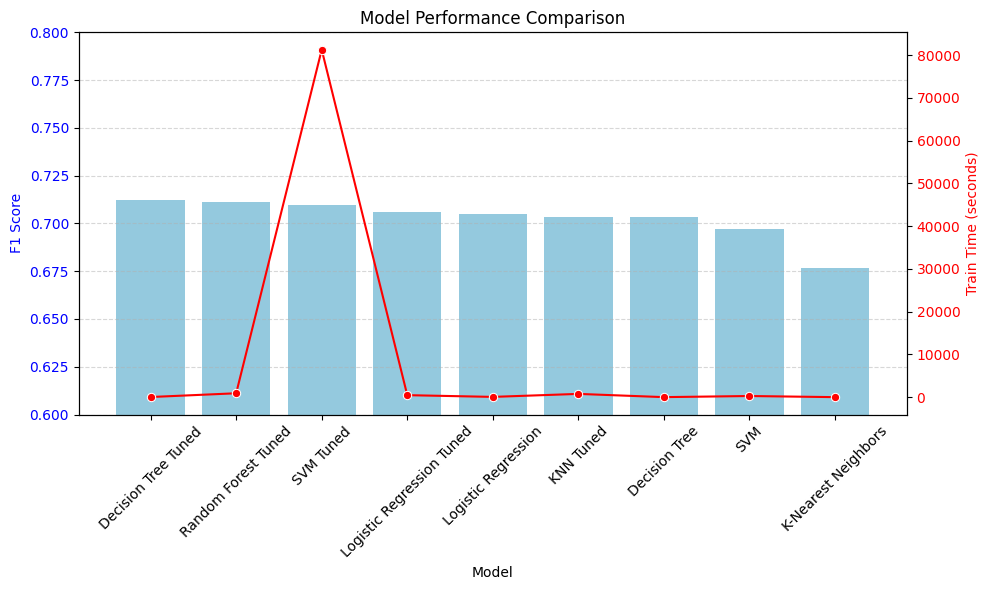

In [ ]:
# plot a graph with bars for test accuracy and line graph for train time in a single graph
# zoom on accuracy between 0.6 and 0.95

results_df = results_df.sort_values('F1 Score', ascending=False).reset_index(drop=True)

fig, ax1 = plt.subplots(figsize=(10, 6))
sns.barplot(x='Model', y='F1 Score', data=results_df, ax=ax1, color='skyblue')
ax1.set_xlabel('Model')
ax1.set_ylabel('F1 Score', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_ylim(0.6, 0.8)

ax2 = ax1.twinx()
sns.lineplot(x='Model', y='Train Time', data=results_df, ax=ax2, color='red', marker='o', errorbar=None)
ax2.set_ylabel('Train Time (seconds)', color='red')
ax2.tick_params(axis='y', labelcolor='red')


plt.title('Model Performance Comparison')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
best_model_name = results_df.iloc[0]['Model']
best_model = best_estimators[best_model_name]

print("Best model selected:", best_model_name)
print("Best parameters:", results_df.iloc[0]['Best Params'])

Best model selected: Decision Tree Tuned
Best parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 20, 'classifier__min_samples_leaf': 8, 'classifier__min_samples_split': 6}


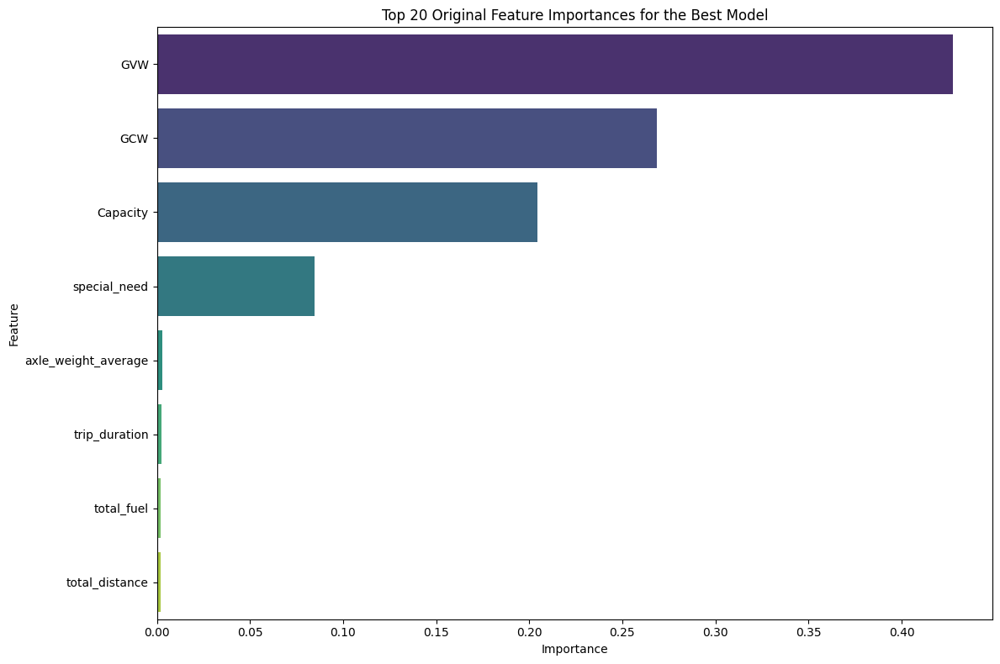

,feature,importance
2,GVW,0.427434
1,GCW,0.268552
0,Capacity,0.204316
4,special_need,0.084632
3,axle_weight_average,0.003147
7,trip_duration,0.002411
6,total_fuel,0.002045
5,total_distance,0.001955


In [ ]:
# Extract feature weights from the fitted best pipeline, but only for the original input features

classifier = best_model.named_steps["classifier"]
preprocessor = best_model.named_steps["preprocessor"]

transformed_feature_names = preprocessor.named_steps["column_transformer"].get_feature_names_out()
original_feature_names = raw_numeric_features + categorical_features

if hasattr(classifier, "feature_importances_"):
    weights = classifier.feature_importances_
elif hasattr(classifier, "coef_"):
    coef = np.asarray(classifier.coef_)
    if coef.ndim == 1:
        weights = np.abs(coef)
    else:
        weights = np.mean(np.abs(coef), axis=0)
else:
    raise AttributeError("The selected model does not expose feature importances or coefficients.")

importance_rows = []
for feature_name, importance in zip(transformed_feature_names, weights):
    cleaned_name = feature_name.split("__", 1)[-1] if "__" in feature_name else feature_name
    matched_feature = None
    for original_feature in original_feature_names:
        if cleaned_name == original_feature or cleaned_name.startswith(original_feature + "_"):
            matched_feature = original_feature
            break
    if matched_feature is not None:
        importance_rows.append((matched_feature, float(importance)))

importance_df = pd.DataFrame(importance_rows, columns=["feature", "importance"])
importance_df = importance_df.groupby("feature", as_index=False)["importance"].sum()
importance_df = importance_df.sort_values("importance", ascending=False)

top_features = importance_df.head(20).copy()

plt.figure(figsize=(12, 8))
sns.barplot(
    data=top_features,
    x="importance",
    y="feature",
    palette="viridis"
)
plt.title("Original Feature Importances for the Best Model")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

importance_df.head(20)

### Extracting the model for deployment

In [ ]:
model_package = {
    "model": best_model,
    "model_name": best_model_name,
    "features": X_train.columns.tolist()
}

joblib.dump(model_package, "best_model_package.joblib")

['best_model_package.joblib']

In [ ]:
#importing the model to check if its valid and then passing test values

package = joblib.load("best_model_package.joblib")

model = package["model"]
features = package["features"]

In [ ]:
print(model)

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('feature_generator',
                                  FunctionTransformer(func=<function add_derived_features at 0x0000018E6B0CA520>)),
                                 ('column_transformer',
                                  ColumnTransformer(transformers=[('num',
                                                                   Pipeline(steps=[('scaler',
                                                                                    StandardScaler())]),
                                                                   ['trip_duration',
                                                                    'total_distance',
                                                                    'total_fuel',
                                                                    'axle_weight_average',
                                                                    'Capacity',
                                           

In [ ]:
#defining raw input data for the best model to make predictions on new data
raw_input = {
    'trip_duration': 908,
    'total_distance': 160.545,
    'total_fuel': 32,
    'axle_weight_average': 2000,
    'Capacity': 20,
    'GCW': 30,
    'GVW': 20,
    'special_need' : 'Flatbed'
}

new_data_df = pd.DataFrame([raw_input])
new_prediction = model.predict(new_data_df)
print(f"Predicted Model for the new data: {new_prediction[0]}")

Predicted Model for the new data: DAF_LF


In [ ]:

### Feature importance — method and key findings
'''
- Method: used the selected best pipeline (`best_model`), extracted the fitted classifier and used its `feature_importances_` (fallback to coef_ / permutation importance if unavailable). 
- Numeric features  trip_duration, total_distance, total_fuel, axle_weight_average, Capacity, GCW, GVW.  
- Top contributors (by importance):
    1. GVW — 0.427434  
    2. GCW — 0.268552  
    3. Capacity — 0.204316 
- Additional contributors: several `special_need` colums are haging a wt of 0.084632
'''

'\n- Method: used the selected best pipeline (`best`), extracted the fitted classifier and used its `feature_importances_` (fallback to coef_ / permutation importance if unavailable). Feature vector maps: first 10 entries = numeric features, remaining entries = one-hot encoded `special_need` categories.  \n- Numeric features (first 10): trip_duration, total_distance, total_fuel, axle_weight_average, Capacity, GCW, GVW, trip_duration_hours, fuel_per_km, avg_speed_kmph.  \n- Top contributors (by importance):\n    1. Capacity — 0.3933  \n    2. GVW — 0.2813  \n    3. GCW — 0.2684  \n- Additional contributors: several `special_need` one-hot columns (importances ≈ 0.0247, 0.0121, 0.0081, 0.0068, 0.0049).  \n- Visualization: bar plot of the top 20 features was produced to show relative importances.\n'